In [1]:
import pandas as pd
import numpy as np

pd.set_option("mode.chained_assignment", None)


import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
from matplotlib import patches as mpatches

plt.rcParams["font.family"] = "Arial"

from pathway_superclass_annotation import PATHWAY_SUPERCLASS
from additives_microbiota.plotting import (
    process_string,
    process_string_pretty_vars,
    ecode_category_colors,
)

ecode_category_colors["Mixture3"] = "mediumpurple"
from additives_microbiota.constants import ADDITIVE_VARS

In [2]:
## All associations

maaslin_res_allAssociations = pd.read_csv(
    "results/maaslin2_pathway/maaslin2_associations_pathway_globalBH.csv"
)

## Only Significant associations

maaslin_res = pd.read_csv("results/maaslin2_pathway/maaslin2_hits_pathway_globalBH.csv")

maaslin_res["superclass"] = maaslin_res["description"].map(PATHWAY_SUPERCLASS)

maaslin_res["metadata"] = maaslin_res["metadata"].map(process_string)

maaslin_res.head()

,feature,metadata,value,coef,stderr,N,N.not.0,pval,qval,food,qval_bh_global,signif_fdr05_global,description,superclass
0,COBALSYN.PWY,Colorants,colorants,-0.045307,0.010420,975,975,0.000015,0.000440,colorants,0.002678,True,adenosylcobalamin salvage from cobinamide I,"Cofactor, prosthetic group, and vitamin biosyn..."
1,PWY.5509,Colorants,colorants,-0.046044,0.010684,975,975,0.000018,0.000512,colorants,0.002712,True,adenosylcobalamin biosynthesis from cobyrinate...,"Cofactor, prosthetic group, and vitamin biosyn..."
2,PWY.6269,Colorants,colorants,-0.046014,0.010679,975,975,0.000018,0.000512,colorants,0.002712,True,adenosylcobalamin salvage from cobinamide II,"Cofactor, prosthetic group, and vitamin biosyn..."
3,ASPASN.PWY,Colorants,colorants,-0.033924,0.008650,975,975,0.000094,0.001922,colorants,0.008868,True,superpathway of L-aspartate and L-asparagine b...,Amino acid biosynthesis
4,PWY.7663,Colorants,colorants,-0.026196,0.006845,975,975,0.000138,0.002453,colorants,0.011963,True,gondoate biosynthesis (anaerobic),Fatty acid and lipid biosynthesis


In [3]:
# maaslin_res[
#     maaslin_res["metadata"].isin(
#         [
#             "sweeteners_glazing_agents",
#             "colorants",
#             "ph_regulators_anti_caking_leavening_agents",
#             "preservatives_antioxidants",
#         ]
#     )
# ].to_csv("results_with_superclass.csv")

maaslin_res[
    maaslin_res["metadata"].isin(maaslin_res["metadata"].value_counts().index[:5])
].to_csv("results_with_superclass.csv")

In [4]:
print("superclasses:", maaslin_res["superclass"].nunique())
maaslin_res["metadata"].value_counts()

superclasses: 11


metadata
Mixture3                                      55
Sweeteners Glazing Agents                     46
Colorants                                     13
pH Regulators Anti Caking Leavening Agents     9
Preservatives Antioxidants                     8
Mixture1                                       5
Mixture2                                       2
Name: count, dtype: int64

In [5]:
de_sweeteners = set(
    maaslin_res[maaslin_res["food"] == "sweeteners_glazing_agents"][
        "description"
    ].unique()
)
de_Mixture3 = set(
    maaslin_res[maaslin_res["food"] == "Mixture3"]["description"].unique()
)

common = de_sweeteners & de_Mixture3
unique_sweeteners = de_sweeteners - de_Mixture3
unique_Mixture3 = de_Mixture3 - de_sweeteners

print("Number of common descriptions:", len(common))
print("Number of unique to sweeteners_glazing_agents:", len(unique_sweeteners))
print("Number of unique to Mixture3:", len(unique_Mixture3))

Number of common descriptions: 43
Number of unique to sweeteners_glazing_agents: 3
Number of unique to Mixture3: 12


In [6]:
def common_additives_set_plot_multi(
    df,
    foods,
    pairs=None,
    ax=None,
    figsize=(6, 4),
    title=None,
    food_col="food",
    desc_col="description",
    common_label="Common pathways",
    common_color="khaki",
    show_counts=True,
    legend_foods=True,
    legend_common=True,
    food_colors=None,
    bbox_to_anchor=(1.02, 0.5),
):
    if pairs is None:
        pairs = [(foods[i], foods[i + 1]) for i in range(0, len(foods) - 1, 2)]

    # NEW: color mapping from provided colors (list or dict), else fallback to colormap
    if isinstance(food_colors, dict):
        color_map = {f: food_colors[f] for f in foods if f in food_colors}
    elif isinstance(food_colors, (list, tuple)) and len(food_colors) > 0:
        if len(food_colors) < len(foods):
            raise ValueError(
                "food_colors must have at least as many colors as `foods`."
            )
        color_map = {f: food_colors[i] for i, f in enumerate(foods)}
    else:
        cmap = plt.get_cmap("tab20")
        n_colors = cmap.N
        color_map = {f: cmap(i % n_colors) for i, f in enumerate(foods)}

    sets = {
        f: set(df.loc[df[food_col] == f, desc_col].dropna().unique())
        for f in set([p[0] for p in pairs] + [p[1] for p in pairs])
    }

    pair_stats = []
    for f1, f2 in pairs:
        s1, s2 = sets.get(f1, set()), sets.get(f2, set())
        common = s1 & s2
        unique1 = s1 - s2
        unique2 = s2 - s1
        pair_stats.append(
            {
                "food1": f1,
                "food2": f2,
                "n_unique1": len(unique1),
                "n_common": len(common),
                "n_unique2": len(unique2),
            }
        )

        print(f"[{f1} vs {f2}] common:", len(common))
        print(f"[{f1} vs {f2}] unique to {f1}:", len(unique1))
        print(f"[{f1} vs {f2}] unique to {f2}:", len(unique2))

    if ax is None:
        fig, ax = plt.subplots(figsize=figsize)
    else:
        fig = ax.figure

    xs = list(range(len(pairs)))
    for x, st in zip(xs, pair_stats):
        f1, f2 = st["food1"], st["food2"]
        n_u1, n_c, n_u2 = st["n_unique1"], st["n_common"], st["n_unique2"]

        ax.bar([x], [n_u1], color=color_map[f1], width=0.5)
        ax.bar([x], [n_c], bottom=[n_u1], color=common_color, width=0.5)
        ax.bar([x], [n_u2], bottom=[n_u1 + n_c], color=color_map[f2], width=0.5)

        if show_counts:
            if n_u1 > 0:
                ax.text(x, n_u1 / 2, str(n_u1), ha="center", va="center")
            if n_c > 0:
                ax.text(x, n_u1 + n_c / 2, str(n_c), ha="center", va="center")
            if n_u2 > 0:
                ax.text(x, n_u1 + n_c + n_u2 / 2, str(n_u2), ha="center", va="center")

    ax.set_yticklabels([])
    ax.set_yticks([])
    ax.set_ylabel("Counts of Significant Pathways")
    ax.set_xticks(xs)
    ax.set_xticklabels(
        [
            f"{process_string_pretty_vars(a)}\nvs\n{process_string_pretty_vars(b)}"
            for a, b in pairs
        ]
    )

    if title is not None:
        ax.set_title(title, y=0.9, x=0.7)

    max_total = max(
        1, max(st["n_unique1"] + st["n_common"] + st["n_unique2"] for st in pair_stats)
    )
    ax.set_ylim(0, max_total * 1.15)

    handles = []
    labels = []

    if legend_common:
        handles.append(mpatches.Patch(color=common_color))
        labels.append(common_label)

    if legend_foods:
        used_foods = []
        for a, b in pairs:
            if a not in used_foods:
                used_foods.append(a)
            if b not in used_foods:
                used_foods.append(b)

        for f in used_foods:
            handles.append(mpatches.Patch(color=color_map[f]))
            labels.append(f"{process_string_pretty_vars(f)} Only")

    if handles:
        ax.legend(
            handles,
            labels,
            frameon=False,
            # loc="center left",
            bbox_to_anchor=bbox_to_anchor,
            ncol=1,
            handlelength=1.0,
            handletextpad=0.4,
            borderaxespad=0.0,
            ncols=1,
            fontsize=8.5,
        )

    return ax, color_map

[sweeteners_glazing_agents vs Mixture3] common: 43
[sweeteners_glazing_agents vs Mixture3] unique to sweeteners_glazing_agents: 3
[sweeteners_glazing_agents vs Mixture3] unique to Mixture3: 12
[sweeteners_glazing_agents vs colorants] common: 11
[sweeteners_glazing_agents vs colorants] unique to sweeteners_glazing_agents: 35
[sweeteners_glazing_agents vs colorants] unique to colorants: 2
[sweeteners_glazing_agents vs preservatives_antioxidants] common: 8
[sweeteners_glazing_agents vs preservatives_antioxidants] unique to sweeteners_glazing_agents: 38
[sweeteners_glazing_agents vs preservatives_antioxidants] unique to preservatives_antioxidants: 0


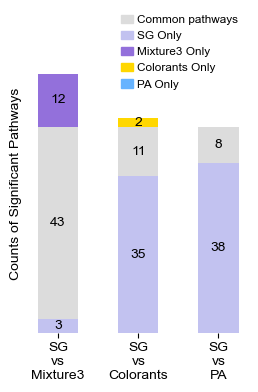

In [7]:
fig, ax = plt.subplots(figsize=(2.7, 4))

ax, cmap = common_additives_set_plot_multi(
    df=maaslin_res,
    foods=[
        "sweeteners_glazing_agents",
        "Mixture3",
        "colorants",
        "preservatives_antioxidants",
    ],
    pairs=[
        ("sweeteners_glazing_agents", "Mixture3"),
        ("sweeteners_glazing_agents", "colorants"),
        ("sweeteners_glazing_agents", "preservatives_antioxidants"),
    ],
    ax=ax,
    title="",
    common_color="gainsboro",
    food_colors=ecode_category_colors,
    bbox_to_anchor=(0.4, 0.8),
)

sns.despine(left=True, bottom=True)

plt.tight_layout()
plt.savefig(
    "../figures/picrust_associations/common_pathways_set_plot_multi.png",
    bbox_inches="tight",
    dpi=300,
)

### Heatmap of significant associations across additives and mixtures

<Axes: xlabel='metadata', ylabel='description'>

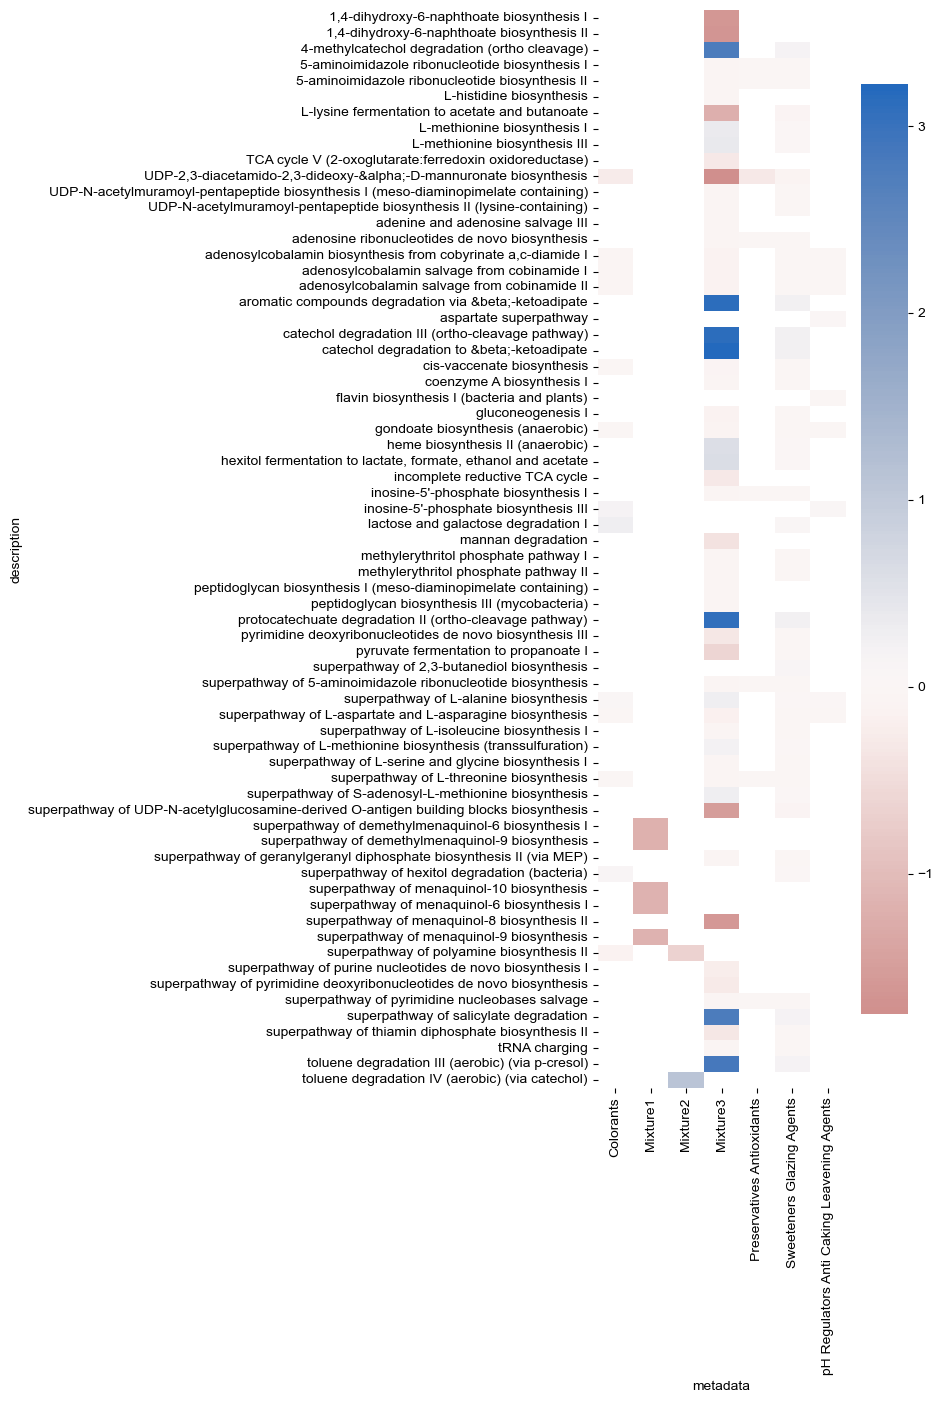

In [8]:
fig, ax = plt.subplots(figsize=(4, 14))
sns.heatmap(
    maaslin_res.pivot_table(
        index="description",
        columns="metadata",
        values="coef",  # aggfunc="sum"
    ),
    ax=ax,
    cmap="vlag_r",
    center=0,
)

# Sankey

In [9]:
def prepare_sankey_food_superclass_direction(
    df,
    food_col="food",
    superclass_col="superclass",
    coef_col="coef",
    feature_col="feature",
    direction_labels=("Down", "Up"),
    include_zero_as=None,  # None to drop zeros; or ("Zero",) style if you want them
):
    """
    Returns node labels and Sankey link arrays (source, target, value)
    for: Food -> Superclass -> Direction, where value = number of pathways.

    direction_labels: (neg_label, pos_label)
    include_zero_as: if not None, zeros are kept with this label (e.g. "Zero")
    """
    d = df[[food_col, superclass_col, coef_col, feature_col]].copy()

    neg_label, pos_label = direction_labels

    def _dir(x):
        if x > 0:
            return pos_label
        if x < 0:
            return neg_label
        return include_zero_as

    d["direction"] = d[coef_col].map(_dir)
    if include_zero_as is None:
        d = d[d["direction"].notna()]

    # count unique pathways per triple, to avoid double-counting if duplicates exist
    g = (
        d.groupby([food_col, superclass_col, "direction"])[feature_col]
        .nunique()
        .reset_index(name="n_pathways")
    )

    foods = list(g[food_col].dropna().unique())
    supers = list(g[superclass_col].dropna().unique())
    dirs = list(g["direction"].dropna().unique())

    node_labels = foods + supers + dirs
    idx = {lab: i for i, lab in enumerate(node_labels)}

    links = []

    # Food -> Superclass
    g_fs = g.groupby([food_col, superclass_col], as_index=False)["n_pathways"].sum()
    for r in g_fs.itertuples(index=False):
        f, s, n = r
        links.append((idx[f], idx[s], int(n)))

    # Superclass -> Direction
    g_sd = g.groupby([superclass_col, "direction"], as_index=False)["n_pathways"].sum()
    for r in g_sd.itertuples(index=False):
        s, dr, n = r
        links.append((idx[s], idx[dr], int(n)))

    source = [x[0] for x in links]
    target = [x[1] for x in links]
    value = [x[2] for x in links]

    return node_labels, source, target, value, g


def plot_sankey_food_superclass_direction(
    node_labels,
    source,
    target,
    value,
    title="Food → Superclass → Direction (Up/Down)",
    font_size=12,
    node_colors=None,  # add
    link_colors=None,  # add
):
    import plotly.graph_objects as go

    fig = go.Figure(
        data=[
            go.Sankey(
                arrangement="snap",
                node=dict(
                    label=node_labels,
                    pad=15,
                    thickness=14,
                    line=dict(width=0.5),
                    color=node_colors,  # add
                ),
                link=dict(
                    source=source,
                    target=target,
                    value=value,
                    color=link_colors,  # add
                ),
            )
        ]
    )

    fig.update_layout(
        title_text=title,
        font_size=font_size,
        margin=dict(l=10, r=10, t=50, b=10),
    )
    fig.show()
    return fig

In [10]:
import plotly.io as pio

run_sankey_analysis = False

if run_sankey_analysis:
    pio.renderers.default = "browser"

    node_labels, source, target, value, _ = prepare_sankey_food_superclass_direction(
        df=maaslin_res,
        food_col="metadata",
        superclass_col="superclass",
        coef_col="coef",
        feature_col="feature",
        direction_labels=("Down", "Up"),
        include_zero_as=None,
    )

    n_nodes = len(node_labels)
    node_colors = [f"hsl({int(360*i/max(n_nodes,1))},50%,50%)" for i in range(n_nodes)]

    direction_color_map = {
        "Up": "hsl(120,45%,45%)",
        "Down": "hsl(0,50%,45%)",
    }

    for i, lab in enumerate(node_labels):
        if lab in direction_color_map:
            node_colors[i] = direction_color_map[lab]

    def _with_alpha(hsl, alpha=0.35):
        h = hsl.split("(")[1].split(",")[0]
        s = hsl.split(",")[1]
        l = hsl.split(",")[2].replace(")", "")
        return f"hsla({h},{s},{l},{alpha})"

    link_colors = [_with_alpha(node_colors[s], alpha=0.35) for s in source]

    fig = plot_sankey_food_superclass_direction(
        node_labels=node_labels,
        source=source,
        target=target,
        value=value,
        title="MaAsLin2 pathways: Additives → Pathway (Superclass) → Direction",
        node_colors=node_colors,
        link_colors=link_colors,
    )

    # fig.write_html("sankey_food_superclass_direction.html")
    # fig.write_image("sankey_food_superclass_direction.png", scale=4)

    fig.write_image("sankey_food_superclass_direction.pdf")

# Volcano plot

In [11]:
from adjustText import adjust_text
import textwrap

In [12]:
ols_res = pd.read_csv(f"results/ols_associations_pathway.csv", index_col=0)
print(ols_res.shape)
print(ols_res["food"].value_counts())
ols_res.head()

(20, 12)
food
Mixture3                                      13
sweeteners_glazing_agents                      5
colorants                                      1
ph_regulators_anti_caking_leavening_agents     1
Name: count, dtype: int64


,feature,beta,se,pval,n,qval_bh,signif_fdr05,description,pathway_id,food,qval_bh_global,signif_fdr05_global
3008,pathway_187,-0.759281,0.167621,0.000006,940,0.001409,True,ethylmalonyl-CoA pathway,PWY-5741,Mixture3,0.012679,True
3009,pathway_89,1.079971,0.241110,0.000007,940,0.001409,True,TCA cycle IV (2-oxoglutarate decarboxylase),P105-PWY,Mixture3,0.012679,True
3010,pathway_246,1.045182,0.256549,0.000046,940,0.004687,True,"superpathway of 2,3-butanediol biosynthesis",PWY-6396,Mixture3,0.026064,True
3011,pathway_63,0.437780,0.109340,0.000062,940,0.004687,True,superpathway of hexitol degradation (bacteria),HEXITOLDEGSUPER-PWY,Mixture3,0.026363,True
3012,pathway_57,1.103367,0.275577,0.000062,940,0.004687,True,"superpathway of glycolysis, pyruvate dehydroge...",GLYCOLYSIS-TCA-GLYOX-BYPASS,Mixture3,0.026363,True


### Loading MaAsLin2 results (all associations, including NS after BH)

In [13]:
maaslin_res_allAssociations["-log10 P-value"] = -np.log10(
    maaslin_res_allAssociations["pval"]
)

maaslin_res_significantAssociations = maaslin_res_allAssociations[
    maaslin_res_allAssociations["signif_fdr05_global"] == True
]

maaslin_res_allAssociations.head()

,feature,metadata,value,coef,stderr,N,N.not.0,pval,qval,food,qval_bh_global,signif_fdr05_global,description,-log10 P-value
0,COBALSYN.PWY,colorants,colorants,-0.045307,0.010420,975,975,0.000015,0.000440,colorants,0.002678,True,adenosylcobalamin salvage from cobinamide I,4.818241
1,PWY.5509,colorants,colorants,-0.046044,0.010684,975,975,0.000018,0.000512,colorants,0.002712,True,adenosylcobalamin biosynthesis from cobyrinate...,4.743424
2,PWY.6269,colorants,colorants,-0.046014,0.010679,975,975,0.000018,0.000512,colorants,0.002712,True,adenosylcobalamin salvage from cobinamide II,4.741956
3,ASPASN.PWY,colorants,colorants,-0.033924,0.008650,975,975,0.000094,0.001922,colorants,0.008868,True,superpathway of L-aspartate and L-asparagine b...,4.025851
4,PWY.7663,colorants,colorants,-0.026196,0.006845,975,975,0.000138,0.002453,colorants,0.011963,True,gondoate biosynthesis (anaerobic),3.860101


In [14]:
def plot_maaslin_volcano_with_labels(
    maaslin_df,
    ols_df=None,
    *,
    pval=0.05,
    x_col="coef",
    y_col="-log10 P-value",
    feature_col="feature",
    desc_col="description",
    highlight_text_type="description",  # "feature" or "description"
    features_to_label=None,  # optional explicit list of features
    figsize=(6, 5),
    ax=None,
    below_color="lightgrey",
    point_alpha=0.4,
    point_size=35,
    threshold_line=True,
    threshold_line_kwargs=None,
    wrap_text=True,
    wrap_width=15,
    label_fontsize=8.5,
    ha="left",
    va="center",
    adjust_kwargs=None,
    title=None,
):
    if ax is None:
        fig, ax = plt.subplots(figsize=figsize)

    threshold = -np.log10(pval)

    if threshold_line:
        tlk = dict(linestyle="--", color="red", linewidth=1, label=f"p={pval}")
        if threshold_line_kwargs:
            tlk.update(threshold_line_kwargs)
        ax.axhline(y=threshold, **tlk)

    above_thresh = maaslin_df[maaslin_df[y_col] >= threshold]
    below_thresh = maaslin_df[maaslin_df[y_col] < threshold]

    ax.scatter(
        below_thresh[x_col],
        below_thresh[y_col],
        alpha=point_alpha,
        s=point_size,
        color=below_color,
        label="Below threshold",
    )

    sns.scatterplot(
        x=x_col,
        y=y_col,
        data=above_thresh,
        alpha=point_alpha,
        s=point_size,
        ax=ax,
        legend=False,
    )

    if features_to_label is None:
        if ols_df is None:
            features_to_label = []
        else:
            features_to_label = maaslin_df[maaslin_df[desc_col].isin(ols_df[desc_col])][
                feature_col
            ].tolist()

    subset = maaslin_df[
        (maaslin_df[feature_col].isin(features_to_label))
        & (maaslin_df[y_col] >= threshold)
    ]

    txt_col = desc_col if highlight_text_type == "description" else feature_col

    texts = []
    for _, row in subset.iterrows():
        label = row[txt_col]
        if wrap_text:
            label = "\n".join(textwrap.wrap(str(label), width=wrap_width))
            label = process_string(label)

        texts.append(
            ax.text(
                row[x_col],
                row[y_col],
                label,
                fontsize=label_fontsize,
                ha=ha,
                va=va,
            )
        )

    ak = dict(arrowprops=dict(arrowstyle="-", color="gray", lw=0.5))
    if adjust_kwargs:
        ak.update(adjust_kwargs)
    adjust_text(texts, ax=ax, **ak)

    if title is not None:
        ax.set_title(title, fontsize=12, fontweight="bold")

    ax.set_xlabel("Effect size (β)")
    ax.set_ylabel("-log10 P-value")

    return ax

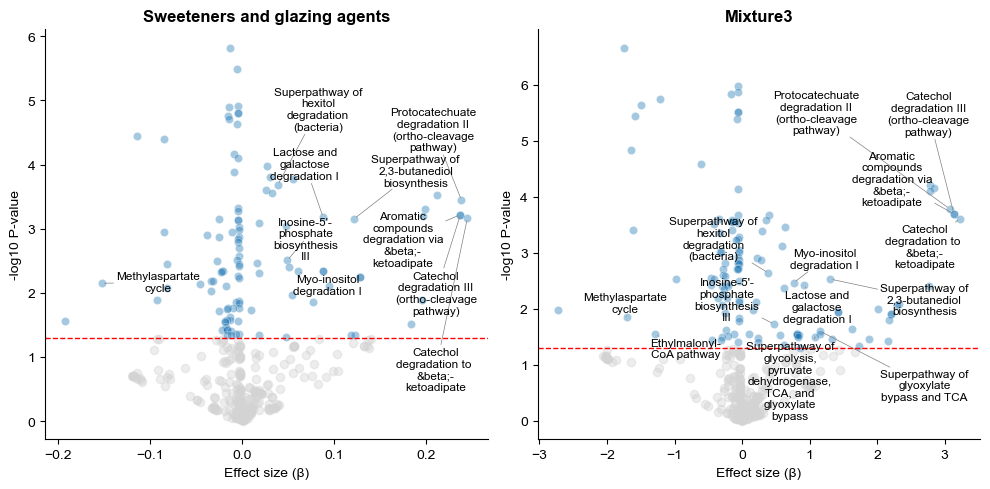

In [15]:
fig, ax = plt.subplots(ncols=2, figsize=(10, 5))

maaslin_res_allAssociations_SG = maaslin_res_allAssociations[
    maaslin_res_allAssociations["food"] == "sweeteners_glazing_agents"
]

plot_maaslin_volcano_with_labels(
    ax=ax[0],
    maaslin_df=maaslin_res_allAssociations_SG,
    ols_df=ols_res,
    highlight_text_type="description",
    wrap_text=True,
    wrap_width=15,
    title="Sweeteners and glazing agents",
)
########################################################
maaslin_res_allAssociations_Mixture3 = maaslin_res_allAssociations[
    maaslin_res_allAssociations["food"] == "Mixture3"
]

plot_maaslin_volcano_with_labels(
    ax=ax[1],
    maaslin_df=maaslin_res_allAssociations_Mixture3,
    ols_df=ols_res,
    highlight_text_type="description",
    wrap_text=True,
    wrap_width=15,
    title="Mixture3",
)
sns.despine()

plt.tight_layout()
plt.savefig(
    "../figures/picrust_associations/volcano_plots.png",
    bbox_inches="tight",
    dpi=300,
)

In [16]:
maaslin_res_allAssociations[maaslin_res_allAssociations["signif_fdr05_global"] == True][
    "metadata"
].value_counts()

metadata
Mixture3                                      55
sweeteners_glazing_agents                     46
colorants                                     13
ph_regulators_anti_caking_leavening_agents     9
preservatives_antioxidants                     8
Mixture1                                       5
Mixture2                                       2
Name: count, dtype: int64

In [17]:
def plot_metadata_stacked_posneg_counts(
    df,
    *,
    metadata_col="metadata",
    coef_col="coef",
    filter_col="signif_fdr05_global",
    filter_value=True,
    figsize=(7, 4),
    fontsize=10,
    rotation=45,
    show_segment_labels=True,
    show_total_labels=False,  # now defaults off
    top_pair_labels=True,
    top_pair_fontsize=10,
):
    d = df[df[filter_col] == filter_value].copy()
    d["coef_sign"] = np.where(d[coef_col] >= 0, "Positive", "Negative")

    ct = (
        d.pivot_table(
            index=metadata_col,
            columns="coef_sign",
            values=coef_col,
            aggfunc="size",
            fill_value=0,
        )
        .reindex(columns=["Negative", "Positive"], fill_value=0)
        .sort_values(by=["Negative", "Positive"], ascending=False)
    )

    fig, ax = plt.subplots(figsize=figsize)

    neg = ct["Negative"].values
    pos = ct["Positive"].values
    x = np.arange(len(ct.index))

    bars_neg = ax.bar(x, neg, label="Negative β coef", color="crimson")
    bars_pos = ax.bar(x, pos, bottom=neg, label="Positive β coef", color="steelblue")

    labels = [process_string_pretty_vars(lbl) for lbl in ct.index.tolist()]

    ax.set_ylabel("Counts (Significant Pathways)")
    ax.set_xlabel("")
    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=rotation, ha="right", rotation_mode="anchor")

    # Remove text within bars by skipping show_segment_labels
    # if show_segment_labels:
    #     for i, (n, p) in enumerate(zip(neg, pos)):
    #         if n > 0:
    #             ax.text(
    #                 i, n / 2, str(int(n)), ha="center", va="center", fontsize=fontsize
    #             )
    #         if p > 0:
    #             ax.text(
    #                 i,
    #                 n + p / 2,
    #                 str(int(p)),
    #                 ha="center",
    #                 va="center",
    #                 fontsize=fontsize,
    #             )

    if show_total_labels:
        totals = neg + pos
        for i, t in enumerate(totals):
            if t > 0:
                ax.text(
                    i,
                    t,
                    str(int(t)),
                    ha="center",
                    va="bottom",
                    fontsize=fontsize,
                    fontweight="bold",
                )

    if top_pair_labels:
        for i, (n, p) in enumerate(zip(neg, pos)):
            total = n + p
            if total <= 0:
                continue

            y = total
            dx = (
                0.06  # horizontal offset in x-axis units (bar centers are at integer x)
            )

            ax.text(
                i - dx,
                y,
                f"{int(p)}",
                ha="right",
                va="bottom",
                fontsize=top_pair_fontsize,
                color="steelblue",
                fontweight="bold",
            )
            ax.text(
                i,
                y,
                " / ",
                ha="center",
                va="bottom",
                fontsize=top_pair_fontsize,
                color="black",
                fontweight="bold",
            )
            ax.text(
                i + dx,
                y,
                f"{int(n)}",
                ha="left",
                va="bottom",
                fontsize=top_pair_fontsize,
                color="crimson",
                fontweight="bold",
            )

    ax.legend(frameon=False)
    sns.despine()
    return fig, ax

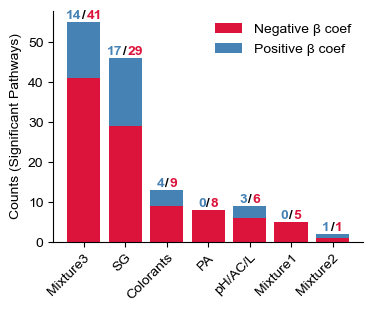

In [18]:
fig, ax = plot_metadata_stacked_posneg_counts(
    maaslin_res_allAssociations,
    rotation=45,
    show_total_labels=False,
    figsize=(4, 3),
)

plt.savefig(
    "../figures/picrust_associations/significant_pathways_counts_in_additives.png",
    bbox_inches="tight",
    dpi=300,
)

## Correlation with Gut diversity

In [19]:
from additives_microbiota.mb_utils import preprocess_picrust_data

In [20]:
meta = pd.read_csv("../../data/metadata_files/meta_zscores.csv", index_col=0)

In [21]:
picrust_data = pd.read_csv(
    "~/WORK/qiime2_2024/qiime_processed_files/exported_rep_seqs/pathways_out/path_abun_unstrat_descrip.tsv",
    sep="\t",
)
desc_dict = picrust_data.set_index("pathway")["description"].to_dict()
picrust_data = picrust_data.drop(columns=["description"]).set_index("pathway").T

In [22]:
data_transformed_filt, id_dict, rev_id_dict, prevalence_filt = preprocess_picrust_data(
    picrust_data,
    data_type="pathway",
    method="log1p",
    min_prev=0.05,
    min_var=1e-8,
)

data_transformed_filt.columns = data_transformed_filt.columns.map(
    lambda x: desc_dict[rev_id_dict[x]]
)

data_transformed_meta = meta.merge(
    data_transformed_filt, left_on="sample-id", right_index=True
)

### Prevalence df prep
prevalence_filt_df = prevalence_filt.to_frame(name="prevalence").reset_index()
prevalence_filt_df["description"] = prevalence_filt_df["pathway"].map(
    lambda x: desc_dict[x]
)
###

print(data_transformed_meta.shape)

(975, 641)


In [23]:
maaslin_res_significantAssociations_SG = maaslin_res_significantAssociations[
    maaslin_res_significantAssociations["food"] == "sweeteners_glazing_agents"
]

print(maaslin_res_significantAssociations_SG.shape)

correlation_threshold = 0.1

corr_colnames = ["shannon_entropy"] + maaslin_res_significantAssociations_SG[
    "description"
].unique().tolist()

corr_with_shannon = (
    data_transformed_meta[corr_colnames]
    .corr()["shannon_entropy"]
    .sort_values(ascending=False)
)

# Remove self-correlation (correlation of shannon_entropy with itself)
corr_with_shannon = corr_with_shannon.drop("shannon_entropy", errors="ignore")
# Remove correlations less than correlation_threshold
corr_with_shannon = corr_with_shannon[corr_with_shannon.abs() > correlation_threshold]
print(corr_with_shannon.shape)
corr_stats_df = corr_with_shannon.to_frame(name="correlation_shannon_entropy")

# Add prevalence to corr_stats_df
corr_stats_df["prevalence"] = corr_stats_df.index.map(
    lambda x: prevalence_filt_df[prevalence_filt_df["description"] == x][
        "prevalence"
    ].values[0]
)

corr_stats_df.reset_index(inplace=True)
corr_stats_df.rename(columns={"index": "description"}, inplace=True)
print(corr_stats_df.shape)

corr_stats_df = maaslin_res_significantAssociations_SG[
    [
        "description",
        "coef",
        "pval",
        "-log10 P-value",
        "metadata",
    ]
].merge(corr_stats_df, on="description", how="right")

corr_stats_df["description"] = corr_stats_df["description"].map(process_string)

corr_stats_df

(46, 14)
(16,)
(16, 3)


,description,coef,pval,-log10 P-value,metadata,correlation_shannon_entropy,prevalence
0,L-lysine fermentation to acetate and butanoate,-0.085438,0.000040,4.393644,sweeteners_glazing_agents,0.348743,0.997087
1,"UDP-2,3-diacetamido-2,3-dideoxy-&alpha;-D-mann...",-0.114655,0.000036,4.446311,sweeteners_glazing_agents,0.346052,0.987379
2,Superpathway of UDP-N-acetylglucosamine-derive...,-0.085118,0.001128,2.947524,sweeteners_glazing_agents,0.256818,0.998058
3,Pyrimidine deoxyribonucleotides de novo biosyn...,-0.025615,0.000712,3.147522,sweeteners_glazing_agents,0.197811,1.000000
4,Superpathway of thiamin diphosphate biosynthes...,-0.024959,0.001328,2.876729,sweeteners_glazing_agents,0.194788,1.000000
5,Catechol degradation to &beta;-ketoadipate,0.244718,0.000681,3.166839,sweeteners_glazing_agents,0.118028,0.516505
6,Aromatic compounds degradation via &beta;-keto...,0.237124,0.000604,3.218897,sweeteners_glazing_agents,0.117386,0.516505
7,Catechol degradation III (ortho-cleavage pathway),0.237124,0.000604,3.218897,sweeteners_glazing_agents,0.117386,0.516505
8,Heme biosynthesis II (anaerobic),0.047490,0.000919,3.036652,sweeteners_glazing_agents,0.107731,1.000000
9,Superpathway of L-methionine biosynthesis (tra...,0.018329,0.000808,3.092504,sweeteners_glazing_agents,-0.144861,1.000000


In [24]:
corr_stats_df["description"].values

array(['L-lysine fermentation to acetate and butanoate',
       'UDP-2,3-diacetamido-2,3-dideoxy-&alpha;-D-mannuronate biosynthesis',
       'Superpathway of UDP-N-acetylglucosamine-derived O-antigen building blocks biosynthesis',
       'Pyrimidine deoxyribonucleotides de novo biosynthesis III',
       'Superpathway of thiamin diphosphate biosynthesis II',
       'Catechol degradation to &beta;-ketoadipate',
       'Aromatic compounds degradation via &beta;-ketoadipate',
       'Catechol degradation III (ortho-cleavage pathway)',
       'Heme biosynthesis II (anaerobic)',
       'Superpathway of L-methionine biosynthesis (transsulfuration)',
       'Superpathway of hexitol degradation (bacteria)',
       'Superpathway of S-adenosyl-L-methionine biosynthesis',
       'Superpathway of L-alanine biosynthesis',
       'L-methionine biosynthesis III', 'L-methionine biosynthesis I',
       'Hexitol fermentation to lactate, formate, ethanol and acetate'],
      dtype=object)

In [25]:
def fusion_barplot(
    df,
    desc_col="description",
    corr_col="correlation_shannon_entropy",
    coef_col="coef",
    prev_col="prevalence",
    sort_by="correlation_shannon_entropy",
    figsize=(12, 7),
    width_ratios=(1.2, 1.2, 0.55),
    corr_xlim=None,
    coef_xlim=None,
    prev_xlim=(0, 1),
    title=None,
):
    d = df[[desc_col, corr_col, coef_col, prev_col]].copy()

    y = list(range(len(d)))
    labels = d[desc_col].astype(str).tolist()

    corr = d[corr_col].astype(float).to_numpy()
    coef = d[coef_col].astype(float).to_numpy()
    prev = d[prev_col].astype(float).to_numpy()

    corr_colors = ["#2ca02c" if v > 0 else "#d62728" for v in corr]
    coef_colors = ["steelblue" if v > 0 else "crimson" for v in coef]
    prev_colors = ["#9e9e9e"] * len(prev)

    fig = plt.figure(figsize=figsize)
    gs = fig.add_gridspec(1, 3, width_ratios=width_ratios, wspace=0.05)

    ax1 = fig.add_subplot(gs[0, 0])
    ax2 = fig.add_subplot(gs[0, 1], sharey=ax1)
    ax3 = fig.add_subplot(gs[0, 2], sharey=ax1)

    # correlation panel
    ax1.barh(y, corr, color=corr_colors)
    ax1.axvline(0, linewidth=0.8)
    ax1.set_yticks(y)
    ax1.set_yticklabels(labels, fontsize=9.3)
    ax1.invert_yaxis()
    if title is not None:
        ax1.set_title(title)
    ax1.set_xlabel("Pearson Correlation\n(with Shannon diversity)")
    if corr_xlim is not None:
        ax1.set_xlim(corr_xlim)

    # correlation legend
    corr_handles = [
        plt.Line2D([0], [0], color="#2ca02c", lw=6, label="Positive"),
        plt.Line2D([0], [0], color="#d62728", lw=6, label="Negative"),
    ]
    ax1.legend(
        handles=corr_handles,
        title="Correlation",
        frameon=False,
        loc="lower right",
        fontsize=9,
        title_fontsize=9,
        handlelength=1.0,
    )

    # coef panel
    ax2.barh(y, coef, color=coef_colors)
    ax2.axvline(0, linewidth=0.8)
    ax2.set_xlabel("Effect size (β)")
    if coef_xlim is not None:
        ax2.set_xlim(coef_xlim)

    # coef legend
    coef_handles = [
        plt.Line2D([0], [0], color="steelblue", lw=6, label="Positive"),
        plt.Line2D([0], [0], color="crimson", lw=6, label="Negative"),
    ]
    legend = ax2.legend(
        handles=coef_handles,
        title="β",
        frameon=False,
        loc="lower right",
        fontsize=9,
        title_fontsize=9,
        handlelength=1.0,
    )

    # prevalence panel
    ax3.barh(y, prev, color=prev_colors)
    ax3.set_xlabel("Prevalence")
    if prev_xlim is not None:
        ax3.set_xlim(prev_xlim)

    ax2.tick_params(axis="y", labelleft=False)
    ax3.tick_params(axis="y", labelleft=False)

    for ax in (ax1, ax2, ax3):
        ax.grid(axis="x", linewidth=0.4, alpha=0.4)
        ax.set_axisbelow(True)

    return fig, (ax1, ax2, ax3)

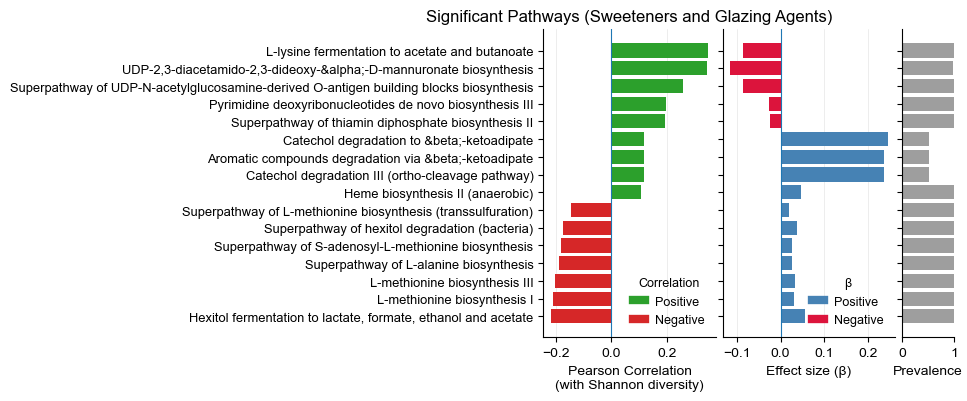

In [26]:
fusion_barplot(
    df=corr_stats_df.sort_values(by="correlation_shannon_entropy", ascending=False),
    sort_by="correlation_shannon_entropy",
    width_ratios=(0.5, 0.5, 0.15),
    prev_xlim=(0, 1),
    figsize=(5.3, 4),
    title="Significant Pathways (Sweeteners and Glazing Agents)",
)

sns.despine()

plt.savefig(
    "../figures/picrust_associations/sweeteners_glazing_agents_pathway_correlation_with_shannon_entropy.png",
    bbox_inches="tight",
    dpi=300,
)